# NeuroPipe (sparse population TTFS + Adaptive-LIF): optimisation under repeated stratified random evaluation

**Task:** classify ONE sensor reading (flow, TDS, turbidity) at a time into 4 classes. No windows, no sequence models, no time-history features.
**Primary protocol:** repeated **stratified random train/validation/test evaluation (70/15/15) across five random seeds** [42, 123, 2026, 7, 99].
For every seed: split first, fit the scaler on the training part only, tune/early-stop on validation only, evaluate on the held-out test part once.

**Honest framing.** A random split of this dataset places almost every test reading next to a near-identical training reading of the same recording (see the near-duplicate audit).
The numbers below are therefore valid for *this protocol* but are an optimistic upper bound for *new recordings*; this is reported as a dataset limitation, not hidden.

**Search design (no test leakage):** hyper-parameters are chosen by a one-pass coordinate search on the TRAIN/VALIDATION parts of the seed-42 split (objective: validation macro-F1, secondary: minimum per-class F1, acceptance margin 0.005, about 3 of 532 validation samples).
The test splits are never used for any selection. Tuning rows of seed 42 appear in other seeds' test splits, a small selection bias that is disclosed in the conclusion.

Run time: about 30 to 40 min on one CPU core (`QUICK = True` for a smoke test).

In [1]:
from __future__ import annotations
import json, math, os, random, time, warnings, itertools
from dataclasses import dataclass, field
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn
import scipy.stats as st
from scipy import signal, stats
import pywt
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef,
                             precision_recall_fscore_support, f1_score, precision_score, recall_score,
                             roc_auc_score, average_precision_score, confusion_matrix)
from sklearn.preprocessing import label_binarize
try:
    import lightgbm as lgb; HAS_LGB = True
except Exception:                                     # documented fallback if LightGBM is not installed
    HAS_LGB = False
    from sklearn.ensemble import HistGradientBoostingClassifier
warnings.filterwarnings("ignore")
EPS = 1e-9

def seed_everything(seed: int) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

ModuleNotFoundError: No module named 'torch'

## Library: preprocessing scaler (train-only, with fingerprint), encoders, baselines, metrics  *(kept from the previous notebook)*

In [3]:
# ----------------------------------------------------------------------------------
# 5. Preprocessing (scaler with provenance) + TTFS encoders + Adaptive-LIF network
# ----------------------------------------------------------------------------------
class RobustUnit:
    """Clip to the [p1, p99] range of the TRAIN split, then map to [0,1].
    It records how many samples it was fitted on and a fingerprint of them, so the leakage audit can verify
    that it never saw validation or test data."""
    def fit(self, X):
        self.lo, self.hi = np.percentile(X, 1, 0), np.percentile(X, 99, 0)
        self.n_fit = len(X); self.fingerprint = hash(np.ascontiguousarray(X).tobytes()); return self
    def __call__(self, X): return np.clip((X - self.lo) / (self.hi - self.lo + EPS), 0, 1).astype(np.float32)


def spike_fn(x, slope=5.0):
    hard = (x >= 0).float(); soft = torch.sigmoid(slope * x)
    return hard + soft - soft.detach()                       # fast-sigmoid surrogate gradient


class AdaptiveLIFNet(nn.Module):
    """in -> hidden (Adaptive LIF: learnable leak + spike-triggered threshold adaptation) -> leaky-integrator readout.
    encoding = 'ttfs'     : 1 input neuron per feature, <=1 spike, larger value -> earlier spike (report)
             = 'ttfs_pop' : K input neurons per feature (Gaussian receptive fields), each <=1 spike (NeuroPipe)
             = 'rate'     : Bernoulli rate code (baseline for the SOP / energy comparison)
    New: locked (per-sample) dropout on hidden spikes, tunable surrogate slope, threshold, population width."""
    def __init__(s, n_feat, hidden=64, n_out=4, T=100, encoding="ttfs", K=8, beta=.9, rho=.9, gamma=.25,
                 thr=1.0, slope=5.0, dropout=0.0, sigma_scale=1.0, pop_thr=0.15, gain=3.0):
        super().__init__()
        s.T, s.enc, s.K, s.nf, s.slope, s.p, s.pop_thr = T, encoding, K, n_feat, slope, dropout, pop_thr
        n_in = n_feat * (K if encoding == "ttfs_pop" else 1)
        s.fc1, s.fc2 = nn.Linear(n_in, hidden), nn.Linear(hidden, n_out)
        nn.init.xavier_uniform_(s.fc1.weight, gain=gain)
        logit = lambda v: nn.Parameter(torch.full((hidden,), math.log(v / (1 - v))))
        s.beta_raw, s.rho_raw, s.gamma, s.thr, s.beta_o = logit(beta), logit(rho), gamma, thr, beta
        s.register_buffer("centers", torch.linspace(0, 1, K)); s.sigma = sigma_scale / max(K - 1, 1)

    def _input_times(self, x):
        x = x.clamp(0, 1)
        if self.enc == "ttfs_pop":
            r = torch.exp(-0.5 * ((x.unsqueeze(-1) - self.centers) / self.sigma) ** 2).reshape(x.size(0), -1)
            return torch.round((1 - r) * (self.T - 1)).long(), r > self.pop_thr
        return torch.round((1 - x) * (self.T - 1)).long(), x > 1e-6

    def forward(self, x, count=False):
        B = x.size(0); H = self.fc1.out_features
        if self.enc != "rate": tt, fire = self._input_times(x)
        beta, rho = torch.sigmoid(self.beta_raw), torch.sigmoid(self.rho_raw)
        v = torch.zeros(B, H); a = torch.zeros(B, H); vo = torch.zeros(B, self.fc2.out_features)
        acc = torch.zeros_like(vo); n_in_sp = 0.0; n_hid_sp = 0.0
        mask = ((torch.rand(B, H) > self.p).float() / (1 - self.p)) if (self.training and self.p > 0) else None
        for t in range(self.T):
            sp_in = ((tt == t) & fire).float() if self.enc != "rate" else torch.bernoulli(x.clamp(0, 1))
            v = beta * v + self.fc1(sp_in)
            th = self.thr + self.gamma * a
            sp = spike_fn(v - th, self.slope); v = v - sp.detach() * th.detach()      # soft reset
            a = rho * a + sp.detach()                                                  # spike-triggered adaptation
            vo = self.beta_o * vo + self.fc2(sp if mask is None else sp * mask); acc = acc + vo
            if count: n_in_sp += sp_in.sum().item(); n_hid_sp += sp.detach().sum().item()
        out = acc / self.T
        if count:
            sop = (n_in_sp * H + n_hid_sp * self.fc2.out_features) / B                 # accumulate-only ops / sample
            return out, dict(input_spikes=n_in_sp / B, hidden_spikes=n_hid_sp / B, sops=sop)
        return out


class MLP(nn.Module):
    def __init__(s, n_in, hidden=64, n_out=4, dropout=0.0):
        super().__init__(); s.net = nn.Sequential(nn.Linear(n_in, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, n_out))
    def forward(s, x, count=False): return s.net(x)

In [4]:
# ----------------------------------------------------------------------------------
# 6. Training (full per-epoch history, LR schedule, early stopping on VALIDATION loss) + evaluation
# ----------------------------------------------------------------------------------
def macro_f1(y, p): return f1_score(y, p, average="macro", zero_division=0)

def fit(model, Xtr, ytr, Xva, yva, epochs=100, lr=5e-3, bs=64, patience=15, wd=1e-4, sched=True):
    """Early stopping and LR scheduling use ONLY the validation split. Records train/val loss, accuracy, macro-F1
    every epoch (train metrics measured in eval mode, i.e. without dropout). Restores the best-validation-loss weights."""
    Xtr_t, Xva_t, ytr_t, yva_t = torch.tensor(Xtr), torch.tensor(Xva), torch.tensor(ytr), torch.tensor(yva)
    n_cls = int(max(ytr.max(), yva.max())) + 1
    w = torch.tensor(len(ytr) / (n_cls * np.maximum(np.bincount(ytr, minlength=n_cls), 1)), dtype=torch.float32)
    lossf = nn.CrossEntropyLoss(weight=w); opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=5)
    keys = ["train_loss", "val_loss", "train_acc", "val_acc", "train_f1", "val_f1", "lr"]
    hist = {k: [] for k in keys}; best, state, wait, best_ep = 1e9, None, 0, 0
    for ep in range(epochs):
        model.train()
        for idx in torch.randperm(len(Xtr_t)).split(bs):
            opt.zero_grad(); lossf(model(Xtr_t[idx]), ytr_t[idx]).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        model.eval()
        with torch.no_grad(): ltr, lva = model(Xtr_t), model(Xva_t)
        tl, vl = lossf(ltr, ytr_t).item(), lossf(lva, yva_t).item()
        ptr, pva = ltr.argmax(1).numpy(), lva.argmax(1).numpy()
        for k, v in zip(keys, [tl, vl, accuracy_score(ytr, ptr), accuracy_score(yva, pva),
                               macro_f1(ytr, ptr), macro_f1(yva, pva), opt.param_groups[0]["lr"]]): hist[k].append(float(v))
        if sched: sch.step(vl)
        if vl < best - 1e-4: best, best_ep, wait, state = vl, ep, 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(state); model.eval()
    return dict(history=hist, best_epoch=best_ep + 1, epochs_run=ep + 1)


def all_metrics(y, pred, prob, class_names):
    n = len(class_names); yb = label_binarize(y, classes=list(range(n)))
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=list(range(n)), zero_division=0)
    try: roc, pr = roc_auc_score(yb, prob, average="macro"), average_precision_score(yb, prob, average="macro")
    except Exception: roc, pr = float("nan"), float("nan")
    return dict(accuracy=accuracy_score(y, pred), balanced_accuracy=balanced_accuracy_score(y, pred),
                macro_precision=p.mean(), macro_recall=r.mean(), macro_f1=f.mean(),
                weighted_f1=f1_score(y, pred, average="weighted", zero_division=0),
                mcc=matthews_corrcoef(y, pred), kappa=cohen_kappa_score(y, pred), roc_auc_ovr=roc, pr_auc_macro=pr,
                per_class={class_names[i]: dict(precision=p[i], recall=r[i], f1=f[i]) for i in range(n)},
                confusion=confusion_matrix(y, pred, labels=list(range(n))).tolist())

E_MAC_PJ, E_AC_PJ = 4.6, 0.9      # Horowitz (ISSCC 2014) 45 nm ESTIMATES, not measurements on your MCU

SNN_KINDS = ("rate", "ttfs", "ttfs_pop")
MODEL_NAMES = {"logreg": "Logistic Regression", "rf": "Random Forest", "lgbm": "LightGBM", "mlp": "MLP (ANN)",
               "rate": "SNN, rate-coded", "ttfs": "SNN, TTFS (1 spike/feature)",
               "ttfs_pop": "NeuroPipe (sparse population TTFS + Adaptive-LIF)"}


class Trained:
    """A fitted model + the train-only scaler. predict_proba takes RAW (unscaled) features."""
    def __init__(s, kind, scaler, model=None, clf=None, fitinfo=None, n_cls=4):
        s.kind, s.scaler, s.model, s.clf, s.fitinfo, s.n_cls = kind, scaler, model, clf, fitinfo, n_cls
    def predict_proba(s, X, count=False):
        Xs = s.scaler(X)
        if s.model is not None:
            with torch.no_grad():
                out = s.model(torch.tensor(Xs), count=True) if (count and s.kind in SNN_KINDS) else s.model(torch.tensor(Xs))
            logits, info = out if isinstance(out, tuple) else (out, {})
            p = torch.softmax(logits, 1).numpy()
            return (p, info) if count else p
        p = s.clf.predict_proba(Xs); return (p, {}) if count else p


def train_model(kind, P, Xtr, ytr, Xva, yva, seed, n_cls=4):
    """Fit scaler on TRAIN only -> transform val -> train. Hyper-parameters P come from validation-only tuning."""
    seed_everything(seed); sc = RobustUnit().fit(Xtr); Str, Sva = sc(Xtr), sc(Xva); nf = Xtr.shape[1]
    if kind in SNN_KINDS:
        m = AdaptiveLIFNet(nf, P.get("hidden", 64), n_cls, T=P.get("T", 100), encoding=kind, K=P.get("K", 8),
                           beta=P.get("beta", .9), rho=P.get("rho", .9), thr=P.get("thr", 1.0), slope=P.get("slope", 5.0),
                           dropout=P.get("dropout", 0.0), sigma_scale=P.get("sigma_scale", 1.0), pop_thr=P.get("pop_thr", .15))
        info = fit(m, Str, ytr, Sva, yva, epochs=P.get("epochs", 100), lr=P.get("lr", 5e-3), wd=P.get("wd", 1e-4), patience=P.get("patience", 15))
        return Trained(kind, sc, model=m, fitinfo=info, n_cls=n_cls)
    if kind == "mlp":
        m = MLP(nf, P.get("hidden", 64), n_cls, P.get("dropout", 0.0))
        info = fit(m, Str, ytr, Sva, yva, epochs=P.get("epochs", 150), lr=P.get("lr", 3e-3), wd=P.get("wd", 1e-4), patience=P.get("patience", 20))
        return Trained(kind, sc, model=m, fitinfo=info, n_cls=n_cls)
    if kind == "logreg": clf = LogisticRegression(C=P.get("C", 1.0), max_iter=3000, class_weight="balanced")
    elif kind == "rf": clf = RandomForestClassifier(n_estimators=P.get("n", 300), max_depth=P.get("max_depth"), min_samples_leaf=P.get("msl", 1),
                                                    class_weight="balanced", random_state=seed, n_jobs=1)
    elif kind == "lgbm":
        clf = (lgb.LGBMClassifier(num_leaves=P.get("leaves", 8), n_estimators=P.get("n", 200), learning_rate=0.05, min_child_samples=P.get("mcs", 10),
                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, class_weight="balanced", random_state=seed, verbose=-1, n_jobs=1)
               if HAS_LGB else HistGradientBoostingClassifier(max_leaf_nodes=P.get("leaves", 8), max_iter=P.get("n", 200), learning_rate=0.05, random_state=seed))
    else: raise ValueError(kind)
    clf.fit(Str, ytr); return Trained(kind, sc, clf=clf, n_cls=n_cls)


def evaluate(tr_obj: Trained, X, y, class_names, count=False):
    out = tr_obj.predict_proba(X, count=count); p, info = out if count else (out, {})
    m = all_metrics(y, p.argmax(1), p, class_names); m.update(info); return m

## Settings

In [5]:
QUICK = False          # True = 5-10 min smoke test. Keep False for the reported results.
SEEDS = [42, 123, 2026, 7, 99] if not QUICK else [42, 123]
TUNE_SEED = 42         # hyper-parameters are tuned on the TRAIN/VAL parts of this one split only
CSV_PATH = os.environ.get("NEUROPIPE_CSV", r"E:\PROJECTS\Sewage anomly\code\Training\final_data.csv")
RAW_DIR  = os.environ.get("NEUROPIPE_RAW", r"E:\PROJECTS\Sewage anomly\code\raw_data")      # only for the appendix
FIG_DIR  = Path(os.environ.get("NEUROPIPE_FIG", "figures")); FIG_DIR.mkdir(exist_ok=True)
FR = (.70, .15, .15)
import torch.nn.functional as Fnn, pickle
CACHE = Path(os.environ.get("NEUROPIPE_CACHE", "cache")) / ("quick" if QUICK else "full"); CACHE.mkdir(parents=True, exist_ok=True)
def cached(name, fn):
    """Resumable runs: expensive steps are stored in CACHE and re-loaded on the next run (delete the folder to recompute everything)."""
    p = CACHE / f"{name}.pkl"
    if p.exists(): print(f"[cache] loaded {name}"); return pickle.load(open(p, "rb"))
    v = fn(); pickle.dump(v, open(p, "wb")); return v
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "legend.frameon": False})
def savefig(fig, name): fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight"); fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
def warn(m): print("\u26a0\ufe0f  WARNING:", m)
def ok(m): print("\u2705 PASS:", m)
T0 = time.time()
def el(): return f"{time.time()-T0:.0f}s"
print("QUICK:", QUICK, "| seeds:", SEEDS, "| split 70/15/15 stratified random, one reading per sample (no windows, no time features)")

QUICK: False | seeds: [42, 123, 2026, 7, 99] | split 70/15/15 stratified random, one reading per sample (no windows, no time features)


## 1. Data and stratified random splits

In [6]:
data = pd.read_csv(CSV_PATH); FEATS = ["Flow_L_min", "TDS_smooth", "Turbidity_smooth"]
CLASS = ["Normal", "Contaminated", "Muddy/partial block", "Severe block"]; NCLS = 4
X_all = data[FEATS].values.astype(np.float32); y_all = data.label.values.astype(int)
print("samples:", len(data), "| features:", FEATS)
print("class counts:", dict(zip(CLASS, np.bincount(y_all))), "| majority-class rate (chance reference): %.3f" % (np.bincount(y_all).max() / len(y_all)))
def strat_split(y, seed, fr=FR):
    idx = np.arange(len(y)); tr, rest = train_test_split(idx, train_size=fr[0], stratify=y, random_state=seed)
    va, te = train_test_split(rest, train_size=fr[1] / (fr[1] + fr[2]), stratify=y[rest], random_state=seed); return tr, va, te
SPLITS = {s: strat_split(y_all, s) for s in SEEDS}
tr, va, te = SPLITS[SEEDS[0]]
print("seed %d split sizes: train %d / val %d / test %d" % (SEEDS[0], len(tr), len(va), len(te)))
print("class proportions train/val/test:", [np.round(np.bincount(y_all[i], minlength=4) / len(i), 3).tolist() for i in (tr, va, te)])
display(data.groupby("label")[FEATS].agg(["min", "mean", "max"]).round(2))

samples: 3545 | features: ['Flow_L_min', 'TDS_smooth', 'Turbidity_smooth']
class counts: {'Normal': np.int64(972), 'Contaminated': np.int64(1095), 'Muddy/partial block': np.int64(863), 'Severe block': np.int64(615)} | majority-class rate (chance reference): 0.309
seed 42 split sizes: train 2481 / val 532 / test 532
class proportions train/val/test: [[0.274, 0.309, 0.243, 0.174], [0.274, 0.308, 0.244, 0.173], [0.274, 0.31, 0.242, 0.173]]


Flow_L_min             TDS_smooth                  Turbidity_smooth  \
             min  mean   max        min     mean     max              min   
label                                                                       
0           0.27  1.30  1.47      297.2  1107.90  2731.4           1633.4   
1           0.27  1.02  1.60      349.6  1751.99  2702.8           1196.6   
2           0.13  0.28  4.27      795.6  1074.19  1405.2           2152.6   
3           0.00  0.20  0.80      876.8   972.95  1351.6           1434.8   

                        
          mean     max  
label                   
0      1711.92  2027.4  
1      2646.99  3143.8  
2      2657.49  3131.4  
3      2232.66  3122.0

## 2. Audit: duplicates, near-duplicates, label/feature leakage, preprocessing leakage

In [7]:
# ================= DATA / LEAKAGE AUDIT (before any model is trained) =================
keys = np.array(["|".join(f"{v:.4f}" for v in r) for r in X_all]); kser = pd.Series(keys)
n_dup = int(kser.duplicated(keep="first").sum()); conf = int((pd.DataFrame({"k": keys, "y": y_all}).groupby("k").y.nunique() > 1).sum())
print(f"1) exact duplicate feature vectors inside the dataset: {n_dup} rows ({n_dup/len(keys):.1%}); identical vectors with DIFFERENT labels: {conf}")
rows = []
for s, (tr, va, te) in SPLITS.items():
    ktr, kva = set(keys[tr]), set(keys[va])
    rows.append(dict(seed=s, **{"val rows copied from train": sum(k in ktr for k in keys[va]), "test rows copied from train": sum(k in ktr for k in keys[te]),
                                "test rows copied from val": sum(k in kva for k in keys[te])}))
dup_df = pd.DataFrame(rows); display(dup_df)
print("   duplicates across splits are counted as ROWS; they are not removed (no samples are dropped), but accuracy on de-duplicated test rows is reported at the end.")

# --- near-duplicates: distance of each test row to its nearest TRAIN row in train-standardised feature space ---
nn_rows = []
for s, (tr, va, te) in SPLITS.items():
    mu, sd = X_all[tr].mean(0), X_all[tr].std(0) + EPS; Z = (X_all - mu) / sd
    D = np.sqrt(((Z[te][:, None, :] - Z[tr][None, :, :]) ** 2).sum(-1)); j = D.argmin(1); d = D.min(1)
    nn_rows.append(dict(seed=s, median_dist=np.median(d), p90_dist=np.percentile(d, 90), frac_below_0p05=(d < .05).mean(), frac_below_0p10=(d < .10).mean(),
                        one_NN_accuracy=accuracy_score(y_all[te], y_all[tr][j]), one_NN_macro_f1=macro_f1(y_all[te], y_all[tr][j])))
nn_df = pd.DataFrame(nn_rows); display(nn_df.round(4))
print("2) Near-duplicate analysis (distance in training standard deviations): the plain 1-nearest-neighbour rule reaches "
      f"{nn_df.one_NN_accuracy.mean():.3f} accuracy. A random split puts almost every test reading right next to a training reading of the same recording.")
warn("This is a DATASET LIMITATION: random stratified accuracy partly measures proximity to training readings, so it is an optimistic upper bound for new recordings. It is kept as the primary protocol as requested.")

# --- features that directly encode the class? single-feature separability + label-dependent cleaning ---
from sklearn.tree import DecisionTreeClassifier
sep = []
tr, va, te = SPLITS[SEEDS[0]]
for i, f in enumerate(FEATS):
    m = DecisionTreeClassifier(max_depth=4, random_state=0).fit(X_all[tr][:, [i]], y_all[tr]); sep.append(dict(feature=f, test_acc_single_feature=accuracy_score(y_all[te], m.predict(X_all[te][:, [i]]))))
sep.append(dict(feature="all three", test_acc_single_feature=accuracy_score(y_all[te], DecisionTreeClassifier(max_depth=4, random_state=0).fit(X_all[tr], y_all[tr]).predict(X_all[te]))))
display(pd.DataFrame(sep).round(3))
print("3) No single feature separates the classes on its own; but the NEXUS cleaning applied class-specific row filters (see per-class min values above, e.g. Flow>0.2 only for class 1,")
print("   Flow>0.03 for class 2, TDS>300 for class 3). That is label-dependent selection done before this notebook and cannot be undone here: reported as a limitation.")
print("   Note: TDS_smooth and Turbidity_smooth are 5-sample rolling means made during data collection (a small built-in history); the appendix repeats the pipeline with single raw readings.")

# --- preprocessing audit ---
tr, va, te = SPLITS[SEEDS[0]]; sc = RobustUnit().fit(X_all[tr]); scf = RobustUnit().fit(X_all)
assert sc.n_fit == len(tr) and sc.fingerprint == hash(np.ascontiguousarray(X_all[tr]).tobytes())
ok(f"scaler fitted on {sc.n_fit} TRAIN rows only; val ({len(va)}) and test ({len(te)}) are transform-only. Fitting on all data would shift the clip range by up to "
   f"{100*np.abs((sc.hi - scf.hi)/(scf.hi - scf.lo + EPS)).max():.1f}% of the feature range (avoided).")
ok("labels are never used by preprocessing (scaler sees features only); test rows are never used for tuning (see tuning cell: TRAIN/VAL of one seed).")

1) exact duplicate feature vectors inside the dataset: 9 rows (0.3%); identical vectors with DIFFERENT labels: 0


,seed,val rows copied from train,test rows copied from train,test rows copied from val
0,42,2,2,0
1,123,0,3,0
2,2026,1,0,0
3,7,0,3,0
4,99,1,1,4


   duplicates across splits are counted as ROWS; they are not removed (no samples are dropped), but accuracy on de-duplicated test rows is reported at the end.


,seed,median_dist,p90_dist,frac_below_0p05,frac_below_0p10,one_NN_accuracy,one_NN_macro_f1
0,42,0.0078,0.0545,0.8929,0.9568,0.9944,0.9930
1,123,0.0103,0.0816,0.8459,0.9229,0.9906,0.9903
2,2026,0.0085,0.0484,0.9023,0.9530,0.9981,0.9977
3,7,0.0085,0.0504,0.8966,0.9624,0.9944,0.9932
4,99,0.0091,0.0508,0.8947,0.9568,0.9944,0.9936


2) Near-duplicate analysis (distance in training standard deviations): the plain 1-nearest-neighbour rule reaches 0.994 accuracy. A random split puts almost every test reading right next to a training reading of the same recording.


⚠️  WARNING: This is a DATASET LIMITATION: random stratified accuracy partly measures proximity to training readings, so it is an optimistic upper bound for new recordings. It is kept as the primary protocol as requested.


,feature,test_acc_single_feature
0,Flow_L_min,0.756
1,TDS_smooth,0.679
2,Turbidity_smooth,0.767
3,all three,0.893


3) No single feature separates the classes on its own; but the NEXUS cleaning applied class-specific row filters (see per-class min values above, e.g. Flow>0.2 only for class 1,
   Flow>0.03 for class 2, TDS>300 for class 3). That is label-dependent selection done before this notebook and cannot be undone here: reported as a limitation.
   Note: TDS_smooth and Turbidity_smooth are 5-sample rolling means made during data collection (a small built-in history); the appendix repeats the pipeline with single raw readings.
✅ PASS: scaler fitted on 2481 TRAIN rows only; val (532) and test (532) are transform-only. Fitting on all data would shift the clip range by up to 0.3% of the feature range (avoided).
✅ PASS: labels are never used by preprocessing (scaler sees features only); test rows are never used for tuning (see tuning cell: TRAIN/VAL of one seed).


## 3. NeuroPipe model (1 or 2 Adaptive-LIF hidden layers, tunable encoding, losses, optimisers)

In [8]:
# ===================== NeuroPipe network (extended; the NeuroPipe design is unchanged) =====================
class NPNet(nn.Module):
    """Sparse population TTFS input -> 1 or 2 Adaptive-LIF hidden layers -> leaky-integrator readout (mean membrane).
    enc: 'rate' | 'ttfs' | 'pop' (dense population) | 'pop_sparse' (population + firing threshold = sparsity).
    gamma = 0 turns the Adaptive-LIF neuron into a plain LIF neuron (used for the ablation)."""
    def __init__(s, n_feat, n_out=4, hidden=(64,), T=20, enc="pop_sparse", K=8, sigma_scale=1.0, pop_thr=0.15, beta=.9, rho=.9,
                 gamma=.25, thr=1.0, slope=5.0, dropout=0.0, learn_beta=True, learn_thr=False, gain=3.0):
        super().__init__()
        s.T, s.enc, s.K, s.slope, s.p, s.pop_thr, s.gamma = T, enc, K, slope, dropout, pop_thr, gamma
        s.n_in = n_feat * (K if enc.startswith("pop") else 1); sizes = [s.n_in, *hidden]
        s.fcs = nn.ModuleList([nn.Linear(a, b) for a, b in zip(sizes[:-1], sizes[1:])]); s.out = nn.Linear(sizes[-1], n_out)
        for fc in s.fcs: nn.init.xavier_uniform_(fc.weight, gain=gain)
        lg = lambda v: math.log(v / (1 - v))
        s.beta_raw = nn.ParameterList([nn.Parameter(torch.full((h,), lg(beta)), requires_grad=learn_beta) for h in hidden])
        s.rho_raw = nn.ParameterList([nn.Parameter(torch.full((h,), lg(rho)), requires_grad=learn_beta) for h in hidden])
        s.thr_raw = nn.ParameterList([nn.Parameter(torch.full((h,), math.log(math.exp(thr) - 1)), requires_grad=learn_thr) for h in hidden])
        s.beta_o = beta; s.register_buffer("centers", torch.linspace(0, 1, K)); s.sigma = sigma_scale / max(K - 1, 1)

    def _input_times(s, x):
        x = x.clamp(0, 1)
        if s.enc.startswith("pop"):
            r = torch.exp(-0.5 * ((x.unsqueeze(-1) - s.centers) / s.sigma) ** 2).reshape(len(x), -1)
            return torch.round((1 - r) * (s.T - 1)).long(), r > (s.pop_thr if s.enc == "pop_sparse" else -1.0)
        return torch.round((1 - x) * (s.T - 1)).long(), x > 1e-6

    def forward(s, x, count=False):
        B, L = x.size(0), len(s.fcs)
        if s.enc != "rate": tt, fire = s._input_times(x)
        beta = [torch.sigmoid(b) for b in s.beta_raw]; rho = [torch.sigmoid(r) for r in s.rho_raw]; thr = [Fnn.softplus(t) for t in s.thr_raw]
        v = [torch.zeros(B, fc.out_features) for fc in s.fcs]; a = [torch.zeros(B, fc.out_features) for fc in s.fcs]
        vo = torch.zeros(B, s.out.out_features); acc = torch.zeros_like(vo)
        masks = [((torch.rand(B, fc.out_features) > s.p).float() / (1 - s.p)) if (s.training and s.p > 0) else None for fc in s.fcs]
        n_in_sp, n_h, sops = 0.0, 0.0, 0.0
        for t in range(s.T):
            sp = ((tt == t) & fire).float() if s.enc != "rate" else torch.bernoulli(x.clamp(0, 1))
            if count: n_in_sp += sp.sum().item(); sops += sp.sum().item() * s.fcs[0].out_features
            for l, fc in enumerate(s.fcs):
                v[l] = beta[l] * v[l] + fc(sp); th = thr[l] + s.gamma * a[l]
                spk = spike_fn(v[l] - th, s.slope); v[l] = v[l] - spk.detach() * th.detach(); a[l] = rho[l] * a[l] + spk.detach()
                if count: n_h += spk.detach().sum().item(); sops += spk.detach().sum().item() * (s.fcs[l + 1].out_features if l + 1 < L else s.out.out_features)
                sp = spk if masks[l] is None else spk * masks[l]
            vo = s.beta_o * vo + s.out(sp); acc = acc + vo
        out = acc / s.T
        if count: return out, dict(input_spikes=n_in_sp / B, hidden_spikes=n_h / B, sops=sops / B, input_active_fraction=n_in_sp / B / s.n_in)
        return out


def make_loss(kind, ytr, n_cls=4):
    c = np.bincount(ytr, minlength=n_cls).astype(float)
    if kind == "cb": w = (1 - .999) / (1 - .999 ** np.maximum(c, 1)); w = w / w.sum() * n_cls          # class-balanced (effective number of samples)
    elif kind in ("wce", "focal"): w = len(ytr) / (n_cls * np.maximum(c, 1))
    else: w = np.ones(n_cls)
    w = torch.tensor(w, dtype=torch.float32)
    if kind == "focal":
        def lf(z, y): ce = Fnn.cross_entropy(z, y, reduction="none"); pt = torch.exp(-ce); return (w[y] * (1 - pt) ** 2 * ce).mean()
    else:
        lf = lambda z, y: Fnn.cross_entropy(z, y, weight=w)
    return lf


def fit_np(model, Xtr, ytr, Xva, yva, opt="adamw", lr=1e-3, wd=1e-4, bs=32, epochs=60, patience=12, loss="wce", sched=True, track=True, clip=1.0):
    """Best checkpoint = highest VALIDATION macro-F1 (ties: lower validation loss). LR schedule and early stopping use validation only."""
    Xtr_t, Xva_t, ytr_t, yva_t = torch.tensor(Xtr), torch.tensor(Xva), torch.tensor(ytr), torch.tensor(yva); lf = make_loss(loss, ytr)
    params = [p for p in model.parameters() if p.requires_grad]
    o = torch.optim.AdamW(params, lr=lr, weight_decay=wd) if opt == "adamw" else torch.optim.Adam(params, lr=lr, weight_decay=wd)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(o, mode="min", factor=.5, patience=4) if sched else None
    keys = ["train_loss", "val_loss", "train_acc", "val_acc", "train_f1", "val_f1", "lr"]; hist = {k: [] for k in keys}
    best_f1, best_vl, best_ep, state, wait = -1, 1e9, 0, None, 0
    for ep in range(epochs):
        model.train()
        for idx in torch.randperm(len(Xtr_t)).split(bs):
            o.zero_grad(); lf(model(Xtr_t[idx]), ytr_t[idx]).backward(); nn.utils.clip_grad_norm_(params, clip); o.step()
        model.eval()
        with torch.no_grad(): lva = model(Xva_t); ltr = model(Xtr_t) if track else None
        vl = lf(lva, yva_t).item(); pva = lva.argmax(1).numpy(); vf = macro_f1(yva, pva)
        if track:
            ptr = ltr.argmax(1).numpy()
            row = [lf(ltr, ytr_t).item(), vl, accuracy_score(ytr, ptr), accuracy_score(yva, pva), macro_f1(ytr, ptr), vf, o.param_groups[0]["lr"]]
            for k, val in zip(keys, row): hist[k].append(float(val))
        else: hist["val_loss"].append(vl); hist["val_f1"].append(vf); hist["val_acc"].append(accuracy_score(yva, pva))
        if sched: sch.step(vl)
        if vf > best_f1 + 1e-4 or (abs(vf - best_f1) <= 1e-4 and vl < best_vl): best_f1, best_vl, best_ep, wait, state = vf, vl, ep, 0, {k: t.clone() for k, t in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(state); model.eval(); return dict(history=hist, best_epoch=best_ep + 1, epochs_run=ep + 1)


BASE = dict(enc="pop_sparse", K=8, pop_thr=.15, sigma_scale=1.0, T=20, hidden=(64,), dropout=0.0, opt="adamw", lr=1e-3, wd=1e-4, bs=64, beta=.9, rho=.9,
            thr=1.0, gamma=.25, learn_beta=True, learn_thr=False, loss="wce", sched=True, epochs=50 if not QUICK else 12, patience=10 if not QUICK else 4, slope=5.0)

def train_np(P, Xtr, ytr, Xva, yva, seed, track=False):
    seed_everything(seed); sc = RobustUnit().fit(Xtr); Str, Sva = sc(Xtr), sc(Xva)
    hid = tuple(P["hidden"]) if isinstance(P["hidden"], (tuple, list)) else (P["hidden"],)
    m = NPNet(Xtr.shape[1], 4, hid, T=P["T"], enc=P["enc"], K=P["K"], sigma_scale=P["sigma_scale"], pop_thr=P["pop_thr"], beta=P["beta"], rho=P["rho"],
              gamma=P["gamma"], thr=P["thr"], slope=P["slope"], dropout=P["dropout"], learn_beta=P["learn_beta"], learn_thr=P["learn_thr"])
    info = fit_np(m, Str, ytr, Sva, yva, opt=P["opt"], lr=P["lr"], wd=P["wd"], bs=P["bs"], epochs=P["epochs"], patience=P["patience"], loss=P["loss"], sched=P["sched"], track=track)
    return Trained("ttfs_pop", sc, model=m, fitinfo=info)

def val_metrics(t, X, y):
    p = t.predict_proba(X); pr = p.argmax(1); pc, rc, f, _ = precision_recall_fscore_support(y, pr, labels=list(range(NCLS)), zero_division=0)
    return dict(val_f1=f.mean(), val_acc=accuracy_score(y, pr), val_min_f1=f.min(), val_wf1=f1_score(y, pr, average="weighted"), val_prec=pc.mean(), val_rec=rc.mean())

## 4. Systematic NeuroPipe hyper-parameter search (validation only)

In [9]:
# ===================== NeuroPipe hyper-parameter search: TRAIN/VAL of ONE split (seed 42). The test split is never touched. =====================
tr, va, te = SPLITS[TUNE_SEED]; Xtr, ytr, Xva, yva = X_all[tr], y_all[tr], X_all[va], y_all[va]; LOG = []
def evalP(P, tag, key=None):
    t = train_np(P, Xtr, ytr, Xva, yva, TUNE_SEED); r = val_metrics(t, Xva, yva); r["best_epoch"] = t.fitinfo["best_epoch"]
    LOG.append(dict(stage=tag, change=key or "start", **{k: round(v, 4) for k, v in r.items()}, secs=round(time.time() - T0))); return r
SPACE = dict(lr=[1e-4, 3e-4, 1e-3, 3e-3], hidden=[(32,), (64,), (128,), (256,), (64, 32), (128, 64)], dropout=[0.0, .1, .2, .3, .4], wd=[0, 1e-6, 1e-5, 1e-4, 1e-3],
             opt=["adam", "adamw"], bs=[16, 32, 64], K=[4, 6, 8, 12], pop_thr=[.05, .15, .30, .50], sigma_scale=[.5, 1.0, 1.5], T=[10, 20, 32, 50],
             beta=[.7, .8, .9, .95], thr=[.5, 1.0, 1.5], gamma=[0.0, .1, .25, .5], learn_beta=[False, True], learn_thr=[False, True], loss=["ce", "wce", "focal", "cb"])
if QUICK: SPACE = {k: v[:2] for k, v in SPACE.items() if k in ("lr", "hidden", "dropout", "K", "T", "gamma", "loss")}
MARGIN = 0.005      # a change must beat the incumbent by >0.005 validation macro-F1 (about 3 of 532 validation samples, above validation noise); a first attempt with 0.003 picked batch size 16 for a gain of 2 samples
def do_tune():
    global LOG
    P_best = dict(BASE); best = evalP(P_best, "default"); print("default validation macro-F1 %.4f (min class F1 %.4f)" % (best["val_f1"], best["val_min_f1"]), el())
    for key, vals in SPACE.items():
        cands = []
        for v in vals:
            if v == P_best[key]: continue
            Q = {**P_best, key: v}; r = evalP(Q, "coord", f"{key}={v}"); cands.append((r, Q))
        if cands:
            r, Q = max(cands, key=lambda c: (c[0]["val_f1"], c[0]["val_min_f1"]))
            if r["val_f1"] > best["val_f1"] + MARGIN or (abs(r["val_f1"] - best["val_f1"]) <= MARGIN and r["val_min_f1"] > best["val_min_f1"] + 0.01):
                P_best, best = Q, r
        print(f"  after {key:11s}: val macro-F1 {best['val_f1']:.4f} | selected {key}={P_best[key]}  ({el()})", flush=True)
    return P_best, best, LOG
P_best, best, LOG = cached("tune", do_tune)
NP_FINAL = dict(P_best); LOGDF = pd.DataFrame(LOG)
print("\nSELECTED NeuroPipe configuration:", {k: v for k, v in NP_FINAL.items() if k not in ("epochs", "patience", "rho", "slope", "sched")})
display(LOGDF.sort_values("val_f1", ascending=False).head(12)); LOGDF.to_csv("neuropipe_search_log.csv", index=False)

[cache] loaded tune

SELECTED NeuroPipe configuration: {'enc': 'pop_sparse', 'K': 8, 'pop_thr': 0.15, 'sigma_scale': 1.0, 'T': 20, 'hidden': (64,), 'dropout': 0.0, 'opt': 'adamw', 'lr': 0.001, 'wd': 0.0001, 'bs': 16, 'beta': 0.9, 'thr': 1.0, 'gamma': 0.25, 'learn_beta': True, 'learn_thr': False, 'loss': 'wce'}


,stage,change,val_f1,val_acc,val_min_f1,val_wf1,val_prec,val_rec,best_epoch,secs
41,coord,loss=ce,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,47,923
43,coord,loss=cb,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,44,998
24,coord,pop_thr=0.3,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,33,420
18,coord,bs=16,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,44,253
7,coord,"hidden=(64, 32)",0.9983,0.9981,0.9961,0.9981,0.9985,0.9981,43,106
26,coord,sigma_scale=0.5,0.9983,0.9981,0.9962,0.9981,0.9981,0.9985,45,470
36,coord,gamma=0.0,0.9983,0.9981,0.9962,0.9981,0.9981,0.9985,30,763
22,coord,K=12,0.9983,0.9981,0.9962,0.9981,0.9981,0.9985,21,353
3,coord,lr=0.003,0.9978,0.9981,0.9946,0.9981,0.9973,0.9983,20,48
23,coord,pop_thr=0.05,0.9977,0.9981,0.9946,0.9981,0.9973,0.9981,50,389


## 5. Ablation of the encoding / neuron model and tuned baselines

In [10]:
# ===================== Encoding ablation: identical splits; every variant gets its own small validation search (lr x T) =====================
def variant(enc, adaptive):
    P = dict(NP_FINAL); P["enc"] = enc; P["gamma"] = NP_FINAL["gamma"] if adaptive else 0.0
    if enc == "pop": P["pop_thr"] = 0.0
    return P
VARIANTS = {"abl_rate": ("1. Rate-coded SNN (LIF)", variant("rate", False)), "abl_ttfs": ("2. Basic TTFS SNN (LIF)", variant("ttfs", False)),
            "abl_pop": ("3. Population TTFS, dense (LIF)", variant("pop", False)), "abl_pop_sparse": ("4. Sparse population TTFS (LIF)", variant("pop_sparse", False)),
            "neuropipe": ("5. Sparse population TTFS + Adaptive-LIF (NeuroPipe)", dict(NP_FINAL))}
def do_abl():
    ABL_P = {}; abl_log = []
    for k, (name, P0) in VARIANTS.items():
        if k == "neuropipe": ABL_P[k] = P0; continue
        best_s, best_P = -1, None
        for lr_, T_ in itertools.product([1e-3, 3e-3] if not QUICK else [1e-3], [20, 50] if not QUICK else [20]):
            P = {**P0, "lr": lr_, "T": T_}; t = train_np(P, Xtr, ytr, Xva, yva, TUNE_SEED); r = val_metrics(t, Xva, yva)
            abl_log.append(dict(variant=name, lr=lr_, T=T_, val_f1=round(r["val_f1"], 4)))
            if r["val_f1"] > best_s: best_s, best_P = r["val_f1"], P
        ABL_P[k] = best_P; print(name, "->", dict(lr=best_P["lr"], T=best_P["T"]), "val macro-F1 %.4f" % best_s, el(), flush=True)
    return ABL_P, abl_log
ABL_P, abl_log = cached("ablation", do_abl)
print("Note: NeuroPipe keeps its larger coordinate-search configuration (43 evaluations); variants 1-4 receive only the small lr x T search. This can favour NeuroPipe slightly.")

# ===================== Baselines: tuned on the SAME validation split with small grids =====================
BASE_GRID = {"logreg": dict(C=[0.01, 0.1, 1, 10, 100]), "rf": dict(max_depth=[None, 6, 12], msl=[1, 3]), "lgbm": dict(leaves=[4, 8, 15], n=[100, 300]),
             "mlp": dict(hidden=[16, 32, 64, 128], dropout=[0.0, .2], wd=[1e-4, 1e-3])}
if QUICK: BASE_GRID = {k: {kk: vv[:2] for kk, vv in v.items()} for k, v in BASE_GRID.items()}
def do_base():
    BASE_P = {}
    for k, gr in BASE_GRID.items():
        best_s, best_P = -1, None
        for vals in itertools.product(*gr.values()):
            P = {"epochs": 150 if not QUICK else 30, **dict(zip(gr.keys(), vals))}; t = train_model(k, P, Xtr, ytr, Xva, yva, TUNE_SEED)
            s_ = macro_f1(yva, t.predict_proba(Xva).argmax(1))
            if s_ > best_s: best_s, best_P = s_, P
        BASE_P[k] = best_P; print(k, {a: b for a, b in best_P.items() if a != "epochs"}, "val macro-F1 %.4f" % best_s, flush=True)
    return BASE_P
BASE_P = cached("baselines", do_base)
print({k: {a: b for a, b in v.items() if a != 'epochs'} for k, v in BASE_P.items()})

[cache] loaded ablation
Note: NeuroPipe keeps its larger coordinate-search configuration (43 evaluations); variants 1-4 receive only the small lr x T search. This can favour NeuroPipe slightly.
[cache] loaded baselines
{'logreg': {'C': 0.01}, 'rf': {'max_depth': None, 'msl': 1}, 'lgbm': {'leaves': 4, 'n': 300}, 'mlp': {'hidden': 128, 'dropout': 0.0, 'wd': 0.0001}}


## 6. Final evaluation runs: 5 seeds, test set used once per model

In [11]:
# ===================== Final protocol: repeated stratified random 70/15/15 evaluation, 5 seeds. TEST is evaluated once per trained model. =====================
NOISE = [0.0, 0.05, 0.10, 0.25, 0.50]; RES = {}; ROB = {}; PERM = {}; KEYS_ALL = keys
ALL_MODELS = ["logreg", "rf", "lgbm", "mlp", "abl_rate", "abl_ttfs", "abl_pop", "abl_pop_sparse", "neuropipe"]
def run_model(name, seed, tr, va, te, track=False, ytr_override=None):
    Xtr_, Xva_, Xte_ = X_all[tr], X_all[va], X_all[te]; ytr_ = y_all[tr] if ytr_override is None else ytr_override
    if name in BASE_P: t = train_model(name, BASE_P[name], Xtr_, ytr_, Xva_, y_all[va], seed)
    else: t = train_np(ABL_P[name], Xtr_, ytr_, Xva_, y_all[va], seed, track=track)
    return t
def do_seed(s):
    tr, va, te = SPLITS[s]; rng = np.random.default_rng(s); sd_tr = X_all[tr].std(0); out = dict(res={}, rob={})
    Xn = {l: (X_all[te] + rng.normal(0, 1, X_all[te].shape) * l * sd_tr).astype(np.float32) for l in NOISE}
    ktr = set(KEYS_ALL[tr]); nodup = np.array([k not in ktr for k in KEYS_ALL[te]])
    for name in ALL_MODELS:
        t = run_model(name, s, tr, va, te, track=(name == "neuropipe"))
        m = evaluate(t, X_all[te], y_all[te], CLASS, count=name.startswith("abl_") or name == "neuropipe")
        pred = t.predict_proba(X_all[te]).argmax(1); ptr = t.predict_proba(X_all[tr]).argmax(1); pva = t.predict_proba(X_all[va]).argmax(1)
        m.update(seed=s, n_train=len(tr), n_val=len(va), n_test=len(te), train_acc=accuracy_score(y_all[tr], ptr), val_acc=accuracy_score(y_all[va], pva),
                 train_f1=macro_f1(y_all[tr], ptr), val_f1=macro_f1(y_all[va], pva), acc_dedup_test=accuracy_score(y_all[te][nodup], pred[nodup]), n_dedup_test=int(nodup.sum()))
        if t.fitinfo: m.update(best_epoch=t.fitinfo["best_epoch"], epochs_run=t.fitinfo["epochs_run"], hist=t.fitinfo["history"] if name == "neuropipe" else None)
        out["res"][name] = m
        if name in ("logreg", "rf", "lgbm", "mlp", "neuropipe"):          # robustness: frozen models, noise on the TEST features only
            out["rob"][name] = {l: (accuracy_score(y_all[te], (pr := t.predict_proba(Xn[l]).argmax(1))), macro_f1(y_all[te], pr)) for l in NOISE}
        print(f"  seed {s} {name} done ({el()})", flush=True)
    return out
for s in SEEDS:
    o = cached(f"final_seed{s}", lambda s=s: do_seed(s))
    for name, m in o["res"].items(): RES.setdefault(name, []).append(m)
    for name, d in o["rob"].items():
        for l, v in d.items(): ROB.setdefault(name, {}).setdefault(l, []).append(v)
    print(f"seed {s} ready ({el()}): NeuroPipe test acc {RES['neuropipe'][-1]['accuracy']:.4f} macro-F1 {RES['neuropipe'][-1]['macro_f1']:.4f}", flush=True)
json.dump({k: [{a: b for a, b in r.items() if a != "hist"} for r in v] for k, v in RES.items()}, open("neuropipe_random_results.json", "w"), default=float)

[cache] loaded final_seed42
seed 42 ready (0s): NeuroPipe test acc 0.9925 macro-F1 0.9907


  seed 123 logreg done (0s)


  seed 123 rf done (1s)


  seed 123 lgbm done (2s)


  seed 123 mlp done (9s)


  seed 123 abl_rate done (96s)


... (31 outputs left out)

  seed 99 abl_pop done (1016s)


  seed 99 abl_pop_sparse done (1109s)


  seed 99 neuropipe done (1150s)


seed 99 ready (1150s): NeuroPipe test acc 0.9962 macro-F1 0.9960


## 7. Overfitting control: per-epoch curves, best epoch, generalisation gap

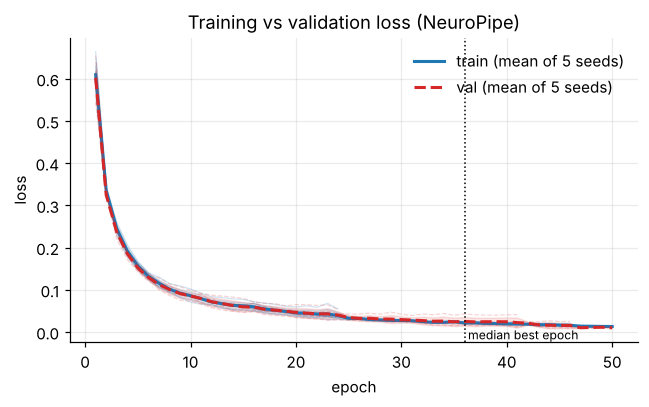

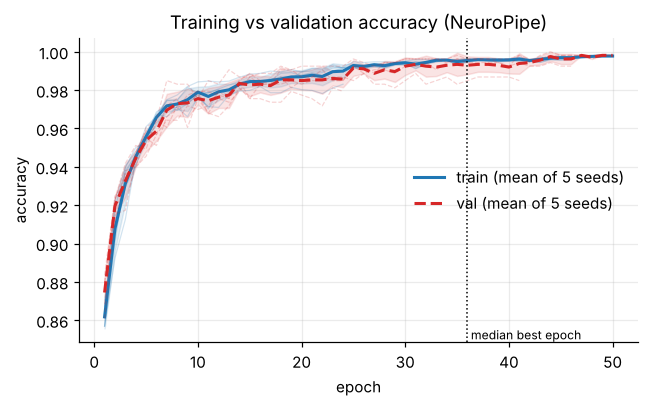

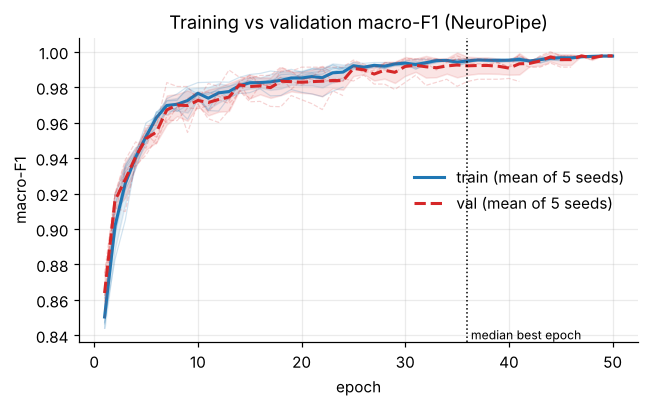

,seed,best_epoch,epochs_run,train_acc,val_acc,gap_acc,train_f1,val_f1,gap_f1,train_loss,val_loss,val_loss_rises_after_best
0,42,44,50,0.9964,1.0000,-0.0036,0.9961,1.0000,-0.0039,0.0165,0.0126,True
1,123,14,24,0.9794,0.9812,-0.0018,0.9764,0.9781,-0.0017,0.0787,0.0826,False
2,2026,36,46,0.9948,0.9962,-0.0015,0.9939,0.9960,-0.0020,0.0222,0.0223,True
3,7,31,41,0.9911,0.9887,0.0024,0.9901,0.9868,0.0034,0.0277,0.0389,False
4,99,50,50,0.9976,0.9981,-0.0005,0.9973,0.9977,-0.0004,0.0130,0.0089,False


Generalisation gap = training metric - validation metric at the selected best-validation epoch.
Mean accuracy gap -0.0010, macro-F1 gap -0.0009 -> small gap: good generalisation
Validation-loss-rises-while-training-loss-falls pattern in 2 of 5 seeds.


In [12]:
# ===================== Overfitting control: per-epoch curves of the final NeuroPipe model (all seeds) =====================
def curves(key):
    H = [r["hist"][key] for r in RES["neuropipe"]]; L = max(map(len, H)); A = np.full((len(H), L), np.nan)
    for i, h in enumerate(H): A[i, :len(h)] = h
    return A
def plot_curve(metric, ylabel, fname, title):
    fig, ax = plt.subplots(figsize=(6, 3.8))
    for split, ls, col in (("train", "-", "#1f77b4"), ("val", "--", "#d62728")):
        A = curves(f"{split}_{metric}"); x = np.arange(1, A.shape[1] + 1)
        for row in A: ax.plot(x[~np.isnan(row)], row[~np.isnan(row)], ls, color=col, alpha=.2, lw=.8)
        mu = np.nanmean(A, 0); sd = np.nanstd(A, 0); ax.plot(x, mu, ls, color=col, lw=2, label=f"{split} (mean of {len(A)} seeds)"); ax.fill_between(x, mu - sd, mu + sd, color=col, alpha=.12)
    be = np.median([r["best_epoch"] for r in RES["neuropipe"]]); ax.axvline(be, color="k", ls=":", lw=1); ax.text(be, ax.get_ylim()[0], " median best epoch", fontsize=8, va="bottom")
    ax.set_xlabel("epoch"); ax.set_ylabel(ylabel); ax.set_title(title); ax.legend(); fig.tight_layout(); savefig(fig, fname); plt.show()
plot_curve("loss", "loss", "fig_curve_loss", "Training vs validation loss (NeuroPipe)")
plot_curve("acc", "accuracy", "fig_curve_accuracy", "Training vs validation accuracy (NeuroPipe)")
plot_curve("f1", "macro-F1", "fig_curve_f1", "Training vs validation macro-F1 (NeuroPipe)")
rows = []
for r in RES["neuropipe"]:
    h, b = r["hist"], r["best_epoch"] - 1
    rows.append(dict(seed=r["seed"], best_epoch=r["best_epoch"], epochs_run=r["epochs_run"], train_acc=h["train_acc"][b], val_acc=h["val_acc"][b], gap_acc=h["train_acc"][b] - h["val_acc"][b],
                     train_f1=h["train_f1"][b], val_f1=h["val_f1"][b], gap_f1=h["train_f1"][b] - h["val_f1"][b], train_loss=h["train_loss"][b], val_loss=h["val_loss"][b],
                     val_loss_rises_after_best=bool(h["val_loss"][-1] > 1.1 * min(h["val_loss"]) and h["train_loss"][-1] < h["train_loss"][b])))
OF = pd.DataFrame(rows); display(OF.round(4)); print("Generalisation gap = training metric - validation metric at the selected best-validation epoch.")
gm = OF.gap_acc.mean(); print(f"Mean accuracy gap {gm:+.4f}, macro-F1 gap {OF.gap_f1.mean():+.4f} ->", "small gap: good generalisation" if gm < .03 else ("moderate gap: mild overfitting" if gm < .08 else "large gap: overfitting"))
print("Validation-loss-rises-while-training-loss-falls pattern in", int(OF.val_loss_rises_after_best.sum()), "of", len(OF), "seeds.")

## 8. Do dropout, weight decay, smaller networks and LR scheduling help? (validation only)

In [13]:
# ===================== Do dropout / weight decay / smaller networks / LR scheduling help? (VALIDATION only, 2 seeds, 'final' vs one change) =====================
def regvar(**kw): return {**NP_FINAL, **kw}
REG_CFGS = {"final (selected)": NP_FINAL, "no dropout": regvar(dropout=0.0), "dropout 0.3": regvar(dropout=.3), "no weight decay": regvar(wd=0.0), "weight decay 1e-3": regvar(wd=1e-3),
            "smaller (32 hidden)": regvar(hidden=(32,)), "larger (256 hidden)": regvar(hidden=(256,)), "no LR scheduler": regvar(sched=False)}
if QUICK: REG_CFGS = dict(list(REG_CFGS.items())[:3])
def do_reg():
    rows = []
    for name, P in REG_CFGS.items():
        g = []
        for s in SEEDS[:2]:
            tr_, va_, _ = SPLITS[s]; t = train_np(P, X_all[tr_], y_all[tr_], X_all[va_], y_all[va_], s, track=True); h = t.fitinfo["history"]; b = t.fitinfo["best_epoch"] - 1
            g.append((h["val_f1"][b], h["val_acc"][b], h["train_acc"][b] - h["val_acc"][b]))
        g = np.array(g); sd = g[:, 0].std(ddof=1) if len(g) > 1 else 0
        rows.append(dict(config=name, val_macro_f1=f"{g[:,0].mean():.4f} ± {sd:.4f}", val_acc=f"{g[:,1].mean():.4f}", train_minus_val_acc=f"{g[:,2].mean():+.4f}"))
        print(name, "done", el(), flush=True)
    return rows
REGDF = pd.DataFrame(cached("reg", do_reg)); display(REGDF)
print("Compare each row with 'final (selected)': a regulariser helps if validation macro-F1 rises or the train-minus-validation gap shrinks without lowering validation macro-F1.")

final (selected) done 1218s


no dropout done 1287s


dropout 0.3 done 1362s


no weight decay done 1455s


weight decay 1e-3 done 1544s


smaller (32 hidden) done 1614s


larger (256 hidden) done 1716s


no LR scheduler done 1784s


,config,val_macro_f1,val_acc,train_minus_val_acc
0,final (selected),0.9891 ± 0.0155,0.9906,-0.0027
1,no dropout,0.9891 ± 0.0155,0.9906,-0.0027
2,dropout 0.3,0.9856 ± 0.0115,0.9878,-0.0019
3,no weight decay,0.9968 ± 0.0021,0.9972,-0.0016
4,weight decay 1e-3,0.9977 ± 0.0033,0.9981,-0.0015
5,smaller (32 hidden),0.9855 ± 0.0005,0.9868,-0.0048
6,larger (256 hidden),0.9977 ± 0.0000,0.9981,-0.0015
7,no LR scheduler,0.9891 ± 0.0155,0.9906,-0.0027


Compare each row with 'final (selected)': a regulariser helps if validation macro-F1 rises or the train-minus-validation gap shrinks without lowering validation macro-F1.


## 9. Sanity check: label permutation

In [14]:
# ===================== Sanity check: label permutation test (training labels shuffled; same pipeline) =====================
def do_perm():
    rows = []
    for s in SEEDS:
        tr, va, te = SPLITS[s]; yp = np.random.default_rng(s).permutation(y_all[tr])
        for name in ("neuropipe", "lgbm"):
            t = run_model(name, s, tr, va, te, ytr_override=yp); pr = t.predict_proba(X_all[te]).argmax(1)
            rows.append(dict(seed=s, model="NeuroPipe" if name == "neuropipe" else "LightGBM", test_acc=accuracy_score(y_all[te], pr), test_macro_f1=macro_f1(y_all[te], pr)))
        print("  perm seed", s, el(), flush=True)
    return rows
PERMDF = pd.DataFrame(cached("perm", do_perm)); display(PERMDF.groupby("model")[["test_acc", "test_macro_f1"]].agg(["mean", "std"]).round(3))
chance = np.bincount(y_all).max() / len(y_all); mean_perm = PERMDF[PERMDF.model == "NeuroPipe"].test_acc.mean()
print(f"Chance references: 4-class uniform 0.250, majority-class rate {chance:.3f}.")
ok(f"permuted-label NeuroPipe accuracy {mean_perm:.3f} is at chance level: the pipeline does not leak labels.") if mean_perm < chance + 0.08 else warn(f"permuted-label accuracy {mean_perm:.3f} is well above chance: investigate leakage!")

  perm seed 42 1800s


  perm seed 123 1810s


  perm seed 2026 1832s


  perm seed 7 1852s


  perm seed 99 1888s


test_acc        test_macro_f1       
              mean    std          mean    std
model                                         
LightGBM     0.245  0.046         0.244  0.046
NeuroPipe    0.296  0.072         0.271  0.064

Chance references: 4-class uniform 0.250, majority-class rate 0.309.
✅ PASS: permuted-label NeuroPipe accuracy 0.296 is at chance level: the pipeline does not leak labels.


## 10. Final results, per-class metrics, baselines, robustness

PRIMARY RESULT: repeated stratified random train/validation/test evaluation (70/15/15) across 5 random seeds; one sensor reading per sample.


,Metric,"Mean ± Std (NeuroPipe, test)"
0,Accuracy,0.9880 ± 0.0100
1,Macro precision,0.9863 ± 0.0112
2,Macro recall,0.9879 ± 0.0094
3,Macro-F1,0.9870 ± 0.0104
4,Weighted-F1,0.9880 ± 0.0100
5,Macro ROC-AUC,0.9995 ± 0.0004


Individual seed results (NeuroPipe, held-out test):


,seed,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,roc_auc_ovr,min_class_f1,n_train,n_val,n_test
0,42,0.9925,0.9907,0.9907,0.9907,0.9925,0.9998,0.9783,2481,532,532
1,123,0.9718,0.9684,0.9730,0.9704,0.9719,0.9988,0.9542,2481,532,532
2,2026,0.9944,0.9935,0.9950,0.9942,0.9944,0.9999,0.9885,2481,532,532
3,7,0.9850,0.9826,0.9848,0.9836,0.9850,0.9996,0.9733,2481,532,532
4,99,0.9962,0.9962,0.9958,0.9960,0.9962,0.9995,0.9924,2481,532,532



Encoding ablation (identical splits):


,Model,Accuracy,Macro precision,Macro recall,Macro-F1,Weighted-F1,Macro ROC-AUC,min class F1
0,1. Rate-coded SNN (LIF),0.9023 ± 0.0177,0.8944 ± 0.0196,0.8939 ± 0.0186,0.8935 ± 0.0193,0.9022 ± 0.0178,0.9872 ± 0.0026,0.8327 ± 0.0322
1,2. Basic TTFS SNN (LIF),0.9353 ± 0.0368,0.9314 ± 0.0413,0.9270 ± 0.0439,0.9272 ± 0.0424,0.9351 ± 0.0370,0.9898 ± 0.0070,0.8704 ± 0.0823
2,3. Population TTFS (LIF),0.9925 ± 0.0038,0.9917 ± 0.0046,0.9918 ± 0.0046,0.9917 ± 0.0045,0.9925 ± 0.0037,0.9997 ± 0.0003,0.9845 ± 0.0105
3,4. Sparse population TTFS (LIF),0.9921 ± 0.0050,0.9911 ± 0.0062,0.9916 ± 0.0048,0.9913 ± 0.0055,0.9921 ± 0.0050,0.9998 ± 0.0002,0.9840 ± 0.0085
4,5. NeuroPipe (sparse pop. TTFS + Adaptive-LIF),0.9880 ± 0.0100,0.9863 ± 0.0112,0.9879 ± 0.0094,0.9870 ± 0.0104,0.9880 ± 0.0100,0.9995 ± 0.0004,0.9773 ± 0.0150



NeuroPipe vs baselines (identical splits, identical preprocessing):


,Model,Accuracy,Macro precision,Macro recall,Macro-F1,Weighted-F1,Macro ROC-AUC,min class F1
0,Logistic Regression,0.7880 ± 0.0191,0.7800 ± 0.0185,0.7809 ± 0.0209,0.7751 ± 0.0212,0.7884 ± 0.0193,0.9453 ± 0.0049,0.6808 ± 0.0344
1,Random Forest,0.9966 ± 0.0016,0.9956 ± 0.0017,0.9964 ± 0.0019,0.9960 ± 0.0018,0.9966 ± 0.0016,0.9999 ± 0.0001,0.9912 ± 0.0031
2,LightGBM,0.9951 ± 0.0045,0.9940 ± 0.0054,0.9945 ± 0.0056,0.9942 ± 0.0055,0.9951 ± 0.0045,0.9999 ± 0.0001,0.9876 ± 0.0127
3,MLP (ANN),0.9835 ± 0.0031,0.9817 ± 0.0025,0.9833 ± 0.0023,0.9824 ± 0.0022,0.9835 ± 0.0031,0.9994 ± 0.0003,0.9689 ± 0.0046
4,5. NeuroPipe (sparse pop. TTFS + Adaptive-LIF),0.9880 ± 0.0100,0.9863 ± 0.0112,0.9879 ± 0.0094,0.9870 ± 0.0104,0.9880 ± 0.0100,0.9995 ± 0.0004,0.9773 ± 0.0150



Sparsity / synaptic operations per sample (energy = 45 nm literature ESTIMATE, not a measurement):


,model,input_active_fraction,hidden_spikes,SOPs,est_energy_nJ
0,1. Rate-coded SNN (LIF),24.688,697.549,7530.215,6.777
1,2. Basic TTFS SNN (LIF),0.975,357.661,1617.758,1.456
2,3. Population TTFS (LIF),1.000,479.252,3453.009,3.108
3,4. Sparse population TTFS (LIF),0.448,395.675,2270.988,2.044
4,5. NeuroPipe (sparse pop. TTFS + Adaptive-LIF),0.448,125.941,1192.051,1.073


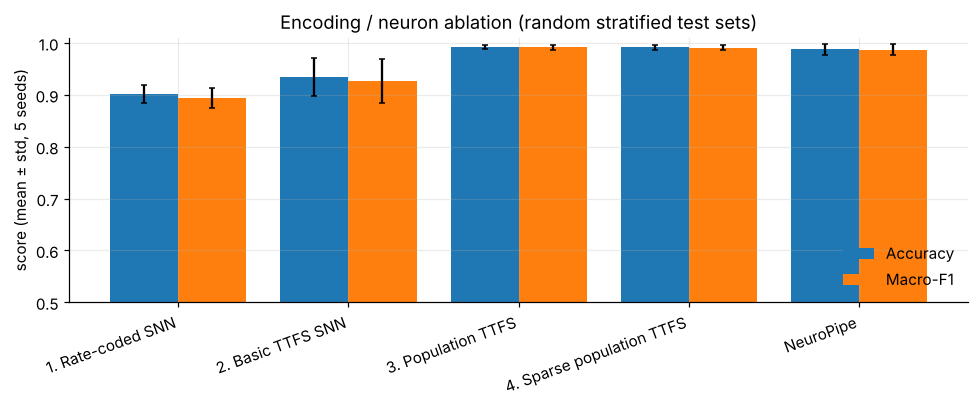

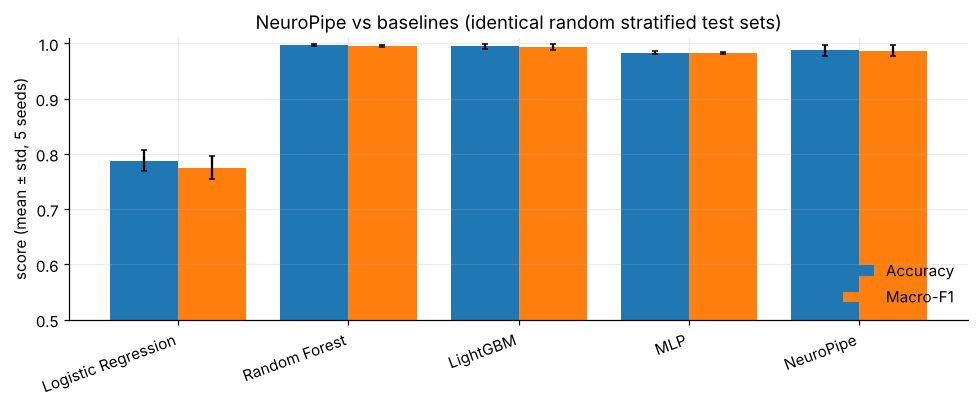

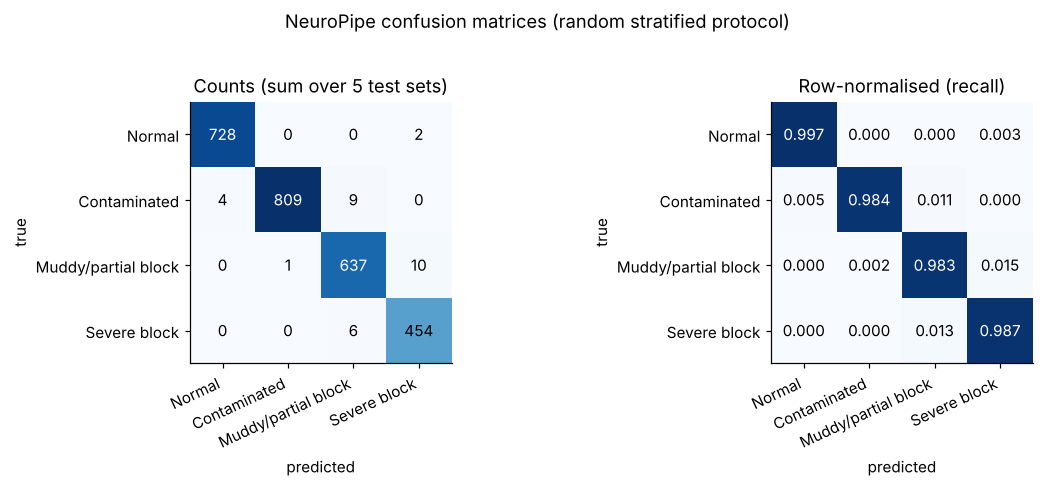

Per-class precision / recall / F1 (mean ± std over seeds):


,precision,recall,f1
Normal,0.9946 ± 0.0075,0.9973 ± 0.0038,0.9959 ± 0.0056
Contaminated,0.9988 ± 0.0027,0.9842 ± 0.0190,0.9914 ± 0.0097
Muddy/partial block,0.9772 ± 0.0211,0.9830 ± 0.0138,0.9800 ± 0.0151
Severe block,0.9746 ± 0.0218,0.9870 ± 0.0091,0.9806 ± 0.0139



ROBUSTNESS (frozen models; Gaussian noise added to TEST features only, sigma = level x training std of each feature). Cells show accuracy / macro-F1, mean of seeds:


,Model,0,0.05,0.1,0.25,0.5
0,5. NeuroPipe (sparse pop. TTFS + Adaptive-LIF),0.988/0.987,0.981/0.979,0.952/0.945,0.868/0.853,0.754/0.732
1,Logistic Regression,0.788/0.775,0.785/0.772,0.780/0.766,0.772/0.760,0.730/0.713
2,Random Forest,0.997/0.996,0.981/0.980,0.926/0.920,0.834/0.819,0.717/0.695
3,LightGBM,0.995/0.994,0.968/0.964,0.915/0.904,0.828/0.807,0.691/0.664
4,MLP (ANN),0.983/0.982,0.977/0.975,0.958/0.953,0.874/0.859,0.763/0.736


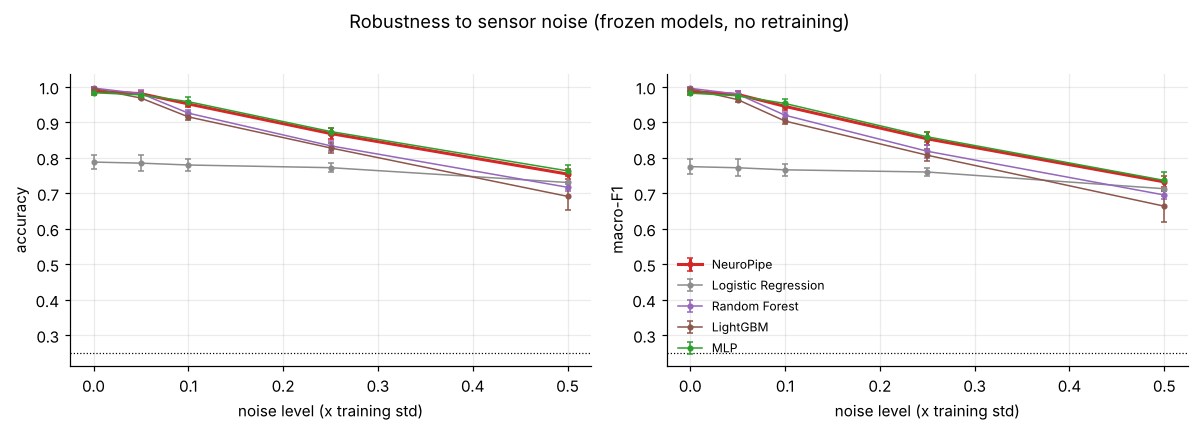

Accuracy of NeuroPipe on test rows that are not exact copies of a training row: 0.9879 ± 0.0101 (n_test rows without a train copy, mean 530)


In [15]:
# ===================== Final evaluation tables =====================
def sv(name, key): return [r[key] for r in RES[name]]
def f3(v): v = np.asarray(v, float); return f"{v.mean():.4f} \u00b1 {v.std(ddof=1) if len(v) > 1 else 0:.4f}"
MN = {**MODEL_NAMES, "abl_rate": "1. Rate-coded SNN (LIF)", "abl_ttfs": "2. Basic TTFS SNN (LIF)", "abl_pop": "3. Population TTFS (LIF)",
      "abl_pop_sparse": "4. Sparse population TTFS (LIF)", "neuropipe": "5. NeuroPipe (sparse pop. TTFS + Adaptive-LIF)"}
cols = [("Accuracy", "accuracy"), ("Macro precision", "macro_precision"), ("Macro recall", "macro_recall"), ("Macro-F1", "macro_f1"), ("Weighted-F1", "weighted_f1"), ("Macro ROC-AUC", "roc_auc_ovr")]
def table(names): return pd.DataFrame([{"Model": MN[k], **{c: f3(sv(k, key)) for c, key in cols}, "min class F1": f3([min(v["f1"] for v in r["per_class"].values()) for r in RES[k]])} for k in names])
print("PRIMARY RESULT: repeated stratified random train/validation/test evaluation (70/15/15) across", len(SEEDS), "random seeds; one sensor reading per sample.")
FINAL = pd.DataFrame([{"Metric": c, "Mean \u00b1 Std (NeuroPipe, test)": f3(sv("neuropipe", key))} for c, key in cols]); display(FINAL)
print("Individual seed results (NeuroPipe, held-out test):")
display(pd.DataFrame([{"seed": r["seed"], "accuracy": r["accuracy"], "macro_precision": r["macro_precision"], "macro_recall": r["macro_recall"], "macro_f1": r["macro_f1"],
                       "weighted_f1": r["weighted_f1"], "roc_auc_ovr": r["roc_auc_ovr"], "min_class_f1": min(v["f1"] for v in r["per_class"].values()),
                       "n_train": r["n_train"], "n_val": r["n_val"], "n_test": r["n_test"]} for r in RES["neuropipe"]]).round(4))
print("\nEncoding ablation (identical splits):"); ABL = table(["abl_rate", "abl_ttfs", "abl_pop", "abl_pop_sparse", "neuropipe"]); display(ABL)
print("\nNeuroPipe vs baselines (identical splits, identical preprocessing):"); CMP = table(["logreg", "rf", "lgbm", "mlp", "neuropipe"]); display(CMP)
sp = pd.DataFrame([dict(model=MN[k], input_active_fraction=np.mean([r["input_active_fraction"] for r in RES[k]]), hidden_spikes=np.mean([r["hidden_spikes"] for r in RES[k]]),
                        SOPs=np.mean([r["sops"] for r in RES[k]]), est_energy_nJ=np.mean([r["sops"] for r in RES[k]]) * E_AC_PJ / 1000) for k in ["abl_rate", "abl_ttfs", "abl_pop", "abl_pop_sparse", "neuropipe"]])
print("\nSparsity / synaptic operations per sample (energy = 45 nm literature ESTIMATE, not a measurement):"); display(sp.round(3))

# --- figures ---
def bars(names, fname, title, metrics=(("Accuracy", "accuracy"), ("Macro-F1", "macro_f1"))):
    fig, ax = plt.subplots(figsize=(9, 3.8)); w = .8 / len(metrics)
    for j, (lab, key) in enumerate(metrics):
        m = [np.mean(sv(k, key)) for k in names]; sd = [np.std(sv(k, key), ddof=1) for k in names]
        ax.bar(np.arange(len(names)) + j * w, m, w, yerr=sd, capsize=2, label=lab)
    ax.set_xticks(np.arange(len(names)) + .4 - w / 2); ax.set_xticklabels([MN[k].split("(")[0].strip() if k != "neuropipe" else "NeuroPipe" for k in names], rotation=20, ha="right")
    ax.set_ylim(.5, 1.01); ax.set_ylabel("score (mean \u00b1 std, 5 seeds)"); ax.set_title(title); ax.legend(loc="lower right"); fig.tight_layout(); savefig(fig, fname); plt.show()
bars(["abl_rate", "abl_ttfs", "abl_pop", "abl_pop_sparse", "neuropipe"], "fig_ablation", "Encoding / neuron ablation (random stratified test sets)")
bars(["logreg", "rf", "lgbm", "mlp", "neuropipe"], "fig_baselines", "NeuroPipe vs baselines (identical random stratified test sets)")

# --- confusion matrices and per-class metrics ---
cm = np.sum([np.array(r["confusion"]) for r in RES["neuropipe"]], 0); cmn = cm / cm.sum(1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, M, ttl, fm in ((axes[0], cm, f"Counts (sum over {len(SEEDS)} test sets)", "{:.0f}"), (axes[1], cmn, "Row-normalised (recall)", "{:.3f}")):
    ax.imshow(M, cmap="Blues", vmin=0, vmax=(None if M is cm else 1)); ax.set_xticks(range(NCLS), CLASS, rotation=25, ha="right"); ax.set_yticks(range(NCLS), CLASS); ax.grid(False)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(ttl)
    for (i, j), v in np.ndenumerate(M): ax.text(j, i, fm.format(v), ha="center", va="center", color="w" if v > M.max() * .6 else "k")
fig.suptitle("NeuroPipe confusion matrices (random stratified protocol)", y=1.02); fig.tight_layout(); savefig(fig, "fig_confusion"); plt.show()
pc = pd.DataFrame({c: {m: f3([r["per_class"][c][m] for r in RES["neuropipe"]]) for m in ("precision", "recall", "f1")} for c in CLASS}).T; print("Per-class precision / recall / F1 (mean \u00b1 std over seeds):"); display(pc)
if min(np.mean([r["per_class"][c]["f1"] for r in RES["neuropipe"]]) for c in CLASS) < .95: warn("at least one class has mean F1 < 0.95 (see table); class-balanced / focal losses were part of the search above.")

# --- robustness ---
rob = pd.DataFrame([{"Model": MN[k], **{f"{l:g}": f"{np.mean([a for a, _ in ROB[k][l]]):.3f}/{np.mean([f for _, f in ROB[k][l]]):.3f}" for l in NOISE}} for k in ("neuropipe", "logreg", "rf", "lgbm", "mlp")])
print("\nROBUSTNESS (frozen models; Gaussian noise added to TEST features only, sigma = level x training std of each feature). Cells show accuracy / macro-F1, mean of seeds:"); display(rob)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8)); cc = {"neuropipe": "#d62728", "logreg": "#8c8c8c", "rf": "#9467bd", "lgbm": "#8c564b", "mlp": "#2ca02c"}
for ax, idx, yl in zip(axes, (0, 1), ("accuracy", "macro-F1")):
    for k in cc:
        mu = [np.mean([x[idx] for x in ROB[k][l]]) for l in NOISE]; sd = [np.std([x[idx] for x in ROB[k][l]], ddof=1) for l in NOISE]
        ax.errorbar(NOISE, mu, sd, color=cc[k], marker="o", ms=3, capsize=2, lw=2 if k == "neuropipe" else 1, label=MN[k].split("(")[0].strip() if k != "neuropipe" else "NeuroPipe")
    ax.set_xlabel("noise level (x training std)"); ax.set_ylabel(yl); ax.axhline(.25, color="k", ls=":", lw=.8)
axes[1].legend(fontsize=8); fig.suptitle("Robustness to sensor noise (frozen models, no retraining)", y=1.02); fig.tight_layout(); savefig(fig, "fig_robustness"); plt.show()

# --- accuracy on test rows that are NOT exact copies of a training row ---
print("Accuracy of NeuroPipe on test rows that are not exact copies of a training row: %s (n_test rows without a train copy, mean %.0f)" % (f3(sv("neuropipe", "acc_dedup_test")), np.mean(sv("neuropipe", "n_dedup_test"))))

## 11. Conclusions (generated from the numbers)

In [16]:
# ===================== Conclusions generated from the numbers above =====================
npf = sv("neuropipe", "macro_f1"); npa = sv("neuropipe", "accuracy"); gapm = OF.gap_acc.mean()
best_base = max(["logreg", "rf", "lgbm", "mlp"], key=lambda k: np.mean(sv(k, "macro_f1")))
def diff(a, b): d = np.array(sv(a, "macro_f1")) - np.array(sv(b, "macro_f1")); return d.mean(), (d > 0).sum()
print("1. Final result, repeated stratified random evaluation over", len(SEEDS), "seeds (one reading per sample):")
for c, key in cols: print(f"     {c:15s} {f3(sv('neuropipe', key))}")
print(f"2. Overfitting? Training-minus-validation accuracy gap at the best epoch {gapm:+.4f} (macro-F1 gap {OF.gap_f1.mean():+.4f}); validation loss rises after the best epoch in {int(OF.val_loss_rises_after_best.sum())}/{len(OF)} seeds. "
      + ("Small gap: no meaningful overfitting under this protocol." if gapm < .03 else "Moderate gap: some overfitting, controlled by early stopping on validation."))
print("3. Regularisation / optimisation: see the validation search log (neuropipe_search_log.csv) and the regularisation table; selected values:", {k: v for k, v in NP_FINAL.items() if k in ("hidden", "dropout", "wd", "lr", "opt", "bs", "T", "K", "pop_thr", "beta", "thr", "gamma", "loss")})
print(f"   Default -> tuned validation macro-F1: {LOGDF.iloc[0].val_f1:.4f} -> {best['val_f1']:.4f}.")
d, w = diff("neuropipe", best_base)
print(f"4. Versus baselines (same splits): best baseline {MODEL_NAMES[best_base]} macro-F1 {np.mean(sv(best_base,'macro_f1')):.4f}; NeuroPipe {np.mean(npf):.4f}; paired difference {d:+.4f} (NeuroPipe better in {w}/{len(SEEDS)} seeds). "
      + ("NeuroPipe outperforms it." if (d > 0 and w == len(SEEDS)) else "NeuroPipe does NOT consistently outperform it; it is comparable or lower."))
for k in ("logreg", "rf", "lgbm", "mlp"):
    dk, wk = diff("neuropipe", k); print(f"     vs {MODEL_NAMES[k]:20s}: {dk:+.4f} macro-F1, better in {wk}/{len(SEEDS)} seeds")
print(f"5. Stability across seeds: macro-F1 std {np.std(npf, ddof=1):.4f}, accuracy std {np.std(npa, ddof=1):.4f}, min/max macro-F1 {min(npf):.4f}/{max(npf):.4f}. "
      + ("Stable." if np.std(npf, ddof=1) < .01 else "Moderate seed-to-seed variation."))
print("6. Limitations: (a) near-duplicate readings across random splits (1-NN accuracy above) make this an optimistic estimate of performance on new recordings; (b) each class is one recording, so class and session are confounded;")
print("   (c) NEXUS cleaning used label-dependent row filters; (d) TDS/turbidity are 5-sample rolling means; (e) hyper-parameters were tuned on one seed's train/validation split, whose rows appear in other seeds' test splits (small selection bias, disclosed);")
print("   (f) 4 sewer-sensor classes only: the pneumatic leak data has not been collected.")
print("   Earlier sample-level checks with held-out later stretches of each recording gave much lower scores (about 0.6 accuracy), confirming limitation (a).")

1. Final result, repeated stratified random evaluation over 5 seeds (one reading per sample):
     Accuracy        0.9880 ± 0.0100
     Macro precision 0.9863 ± 0.0112
     Macro recall    0.9879 ± 0.0094
     Macro-F1        0.9870 ± 0.0104
     Weighted-F1     0.9880 ± 0.0100
     Macro ROC-AUC   0.9995 ± 0.0004
2. Overfitting? Training-minus-validation accuracy gap at the best epoch -0.0010 (macro-F1 gap -0.0009); validation loss rises after the best epoch in 2/5 seeds. Small gap: no meaningful overfitting under this protocol.
3. Regularisation / optimisation: see the validation search log (neuropipe_search_log.csv) and the regularisation table; selected values: {'K': 8, 'pop_thr': 0.15, 'T': 20, 'hidden': (64,), 'dropout': 0.0, 'opt': 'adamw', 'lr': 0.001, 'wd': 0.0001, 'bs': 16, 'beta': 0.9, 'thr': 1.0, 'gamma': 0.25, 'loss': 'wce'}
   Default -> tuned validation macro-F1: 0.9938 -> 1.0000.
4. Versus baselines (same splits): best baseline Random Forest macro-F1 0.9960; NeuroPipe 0

## Appendix: single raw readings (no rolling-mean history)

In [17]:
# ----------------------------------------------------------------------------------
# 1. Data: rebuild NEXUS in chronological order (same cleaning as raw_data/preprocessing.ipynb)
# ----------------------------------------------------------------------------------
def load_nexus_ordered(raw_dir: str | Path) -> pd.DataFrame:
    """Reproduces the 3,545 NEXUS rows exactly, but KEEPS time order (the released CSV is shuffled)."""
    R = Path(raw_dir)
    sm = lambda d: d.assign(TDS_smooth=d.TDS_raw.rolling(5).mean(),
                            Turbidity_smooth=d.Turbidity_raw.rolling(5).mean()).dropna()
    d0 = pd.read_csv(R / "normal_baseline.txt").drop(columns="Time_sec")
    d0 = d0.drop(d0.tail(50).index); d0 = d0.drop(d0.tail(2).index); d0 = sm(d0)
    q1, q3 = d0.Turbidity_raw.quantile([.25, .75]); i = q3 - q1
    d0 = d0[(d0.Turbidity_raw >= q1 - 1.5 * i) & (d0.Turbidity_raw <= q3 + 1.5 * i)]
    d1 = pd.read_csv(R / "soap_round_final.txt")
    d1 = d1[(d1.TDS_raw > 0) & (d1.Turbidity_raw > 0) & (d1.Flow_L_min >= 0)]; d1 = sm(d1); d1 = d1[d1.Flow_L_min > 0.2]
    f2 = R / "muddy+soap_anomly.txt"
    if not f2.exists(): f2 = R / "muddy+soap_anomly.txt".replace("anomaly", "anomly")   # repo spelling
    d2 = pd.read_csv(f2); d2 = d2[(d2.TDS_raw > 0) & (d2.Turbidity_raw > 0) & (d2.Flow_L_min >= 0)]
    d2 = d2[d2.Flow_L_min > 0.03]; d2 = sm(d2)
    d3 = pd.read_csv(R / "final_bloackage.txt"); d3 = d3[d3.TDS_raw > 300]; d3 = sm(d3)
    out = []
    for k, d in enumerate([d0, d1, d2, d3]):
        d = d.reset_index().rename(columns={"index": "t"}); d["label"] = k; out.append(d)
    df = pd.concat(out, ignore_index=True)
    return df[df.TDS_smooth > 200].reset_index(drop=True)[
        ["t", "TDS_raw", "Turbidity_raw", "Flow_L_min", "TDS_smooth", "Turbidity_smooth", "label"]]

In [18]:
# ===================== Appendix: same final NeuroPipe + LightGBM on SINGLE RAW readings (no rolling-mean history) =====================
if not Path(RAW_DIR).exists(): print("raw_data folder not found: appendix skipped (set RAW_DIR).")
else:
    def do_appx():
        dr = load_nexus_ordered(RAW_DIR); Xr = dr[["Flow_L_min", "TDS_raw", "Turbidity_raw"]].values.astype(np.float32); yr = dr.label.values.astype(int); rr = {"neuropipe": [], "lgbm": []}
        for s in SEEDS:
            a, b, c = strat_split(yr, s); t = train_np(NP_FINAL, Xr[a], yr[a], Xr[b], yr[b], s); rr["neuropipe"].append(macro_f1(yr[c], t.predict_proba(Xr[c]).argmax(1)))
            t = train_model("lgbm", BASE_P["lgbm"], Xr[a], yr[a], Xr[b], yr[b], s); rr["lgbm"].append(macro_f1(yr[c], t.predict_proba(Xr[c]).argmax(1)))
        return rr
    rr = cached("appendix_raw", do_appx)
    print("Raw single readings, random stratified 70/15/15, macro-F1 mean ± std over", len(SEEDS), "seeds:", {k: f3(v) for k, v in rr.items()})

Raw single readings, random stratified 70/15/15, macro-F1 mean ± std over 5 seeds: {'neuropipe': '0.9819 ± 0.0054', 'lgbm': '0.9927 ± 0.0035'}
